# Wine Quality Prediction Using Machine Learning

**Oasis Infobyte (OIBSIP) | Level 2 | Task 2**

## Introduction
Wine quality prediction uses measurements of physicochemical properties to estimate quality categories. Machine learning can learn multivariate patterns from historical measurements and compare how different classification algorithms perform. This analysis uses the real UCI red wine dataset and compares Random Forest, SVC, and SGD classifiers.

The original quality score is retained. For classification it is grouped into Low Quality (<= 5), Medium Quality (6), and High Quality (>= 7). The dataset is small and imbalanced, so the project reports macro-averaged metrics in addition to accuracy.

In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

warnings.filterwarnings("ignore", category=FutureWarning)
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data_preprocessing import load_and_clean_data, save_cleaned_data, split_features_target
from model_training import train_models
from model_evaluation import evaluate_models, save_feature_importance
from run_project import create_eda_charts, write_findings

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "winequality-red.csv"
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_wine_data.csv"
REPORTS_PATH = PROJECT_ROOT / "reports"
VISUALIZATIONS_PATH = PROJECT_ROOT / "visualizations"
MODELS_PATH = PROJECT_ROOT / "models"
if not RAW_PATH.exists():
    raise FileNotFoundError(f"Place the UCI winequality-red.csv file at {RAW_PATH}")
sns.set_theme(style="whitegrid")
print(f"Project directory: {PROJECT_ROOT}")

Project directory: C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-WineQualityPrediction


## Load and inspect the dataset
The UCI file uses semicolons as delimiters. First review its dimensions, schema, missing values, duplicates, and descriptive statistics.

In [2]:
raw_data = pd.read_csv(RAW_PATH, sep=";")
print("First five rows:")
display(raw_data.head())
print("Shape:", raw_data.shape)
print("Columns:", raw_data.columns.tolist())
print("Data types:")
display(raw_data.dtypes.to_frame("dtype"))
print("Missing values by column:")
display(raw_data.isna().sum().to_frame("missing"))
print("Duplicate rows:", int(raw_data.duplicated().sum()))
print("Descriptive statistics:")
display(raw_data.describe().T)

First five rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Shape: (1599, 12)
Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
Data types:


,dtype
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


Missing values by column:


,missing
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Duplicate rows: 240
Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


## Data cleaning
Exact duplicate rows are removed. Feature values are checked as numeric and missing feature values, if any, are filled with their feature median. Missing target values are not guessed. The raw file is not changed.

In [3]:
data, audit = load_and_clean_data(RAW_PATH)
save_cleaned_data(data, PROCESSED_PATH)
print("Cleaning audit:", audit)
print("Cleaned shape:", data.shape)
print("Missing values after cleaning:", int(data.isna().sum().sum()))
print("Numeric feature ranges (review for unusual values):")
display(data.drop(columns="quality_label").describe().loc[["min", "max"]].T)
print(f"Saved cleaned data to {PROCESSED_PATH}")

Cleaning audit: {'rows_loaded': 1599, 'duplicate_rows_removed': 240, 'missing_values_before_cleaning': 0, 'rows_after_cleaning': 1359, 'missing_values_after_cleaning': 0}
Cleaned shape: (1359, 13)
Missing values after cleaning: 0
Numeric feature ranges (review for unusual values):


,min,max
fixed acidity,4.60000,15.90000
volatile acidity,0.12000,1.58000
citric acid,0.00000,1.00000
residual sugar,0.90000,15.50000
chlorides,0.01200,0.61100
free sulfur dioxide,1.00000,72.00000
total sulfur dioxide,6.00000,289.00000
density,0.99007,1.00369
pH,2.74000,4.01000
sulphates,0.33000,2.00000


Saved cleaned data to C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-WineQualityPrediction\data\processed\cleaned_wine_data.csv


## Exploratory data analysis
Quality scores are not equally represented. The following charts and descriptive statistics provide a first look at the data; correlations are associations, not causal effects.

Mean, median, standard deviation, minimum, and maximum:


,mean,median,std,min,max
fixed acidity,8.310596,7.9000,1.736990,4.60000,15.90000
volatile acidity,0.529478,0.5200,0.183031,0.12000,1.58000
citric acid,0.272333,0.2600,0.195537,0.00000,1.00000
residual sugar,2.523400,2.2000,1.352314,0.90000,15.50000
chlorides,0.088124,0.0790,0.049377,0.01200,0.61100
free sulfur dioxide,15.893304,14.0000,10.447270,1.00000,72.00000
total sulfur dioxide,46.825975,38.0000,33.408946,6.00000,289.00000
density,0.996709,0.9967,0.001869,0.99007,1.00369
pH,3.309787,3.3100,0.155036,2.74000,4.01000
sulphates,0.658705,0.6200,0.170667,0.33000,2.00000


quality_distribution.png


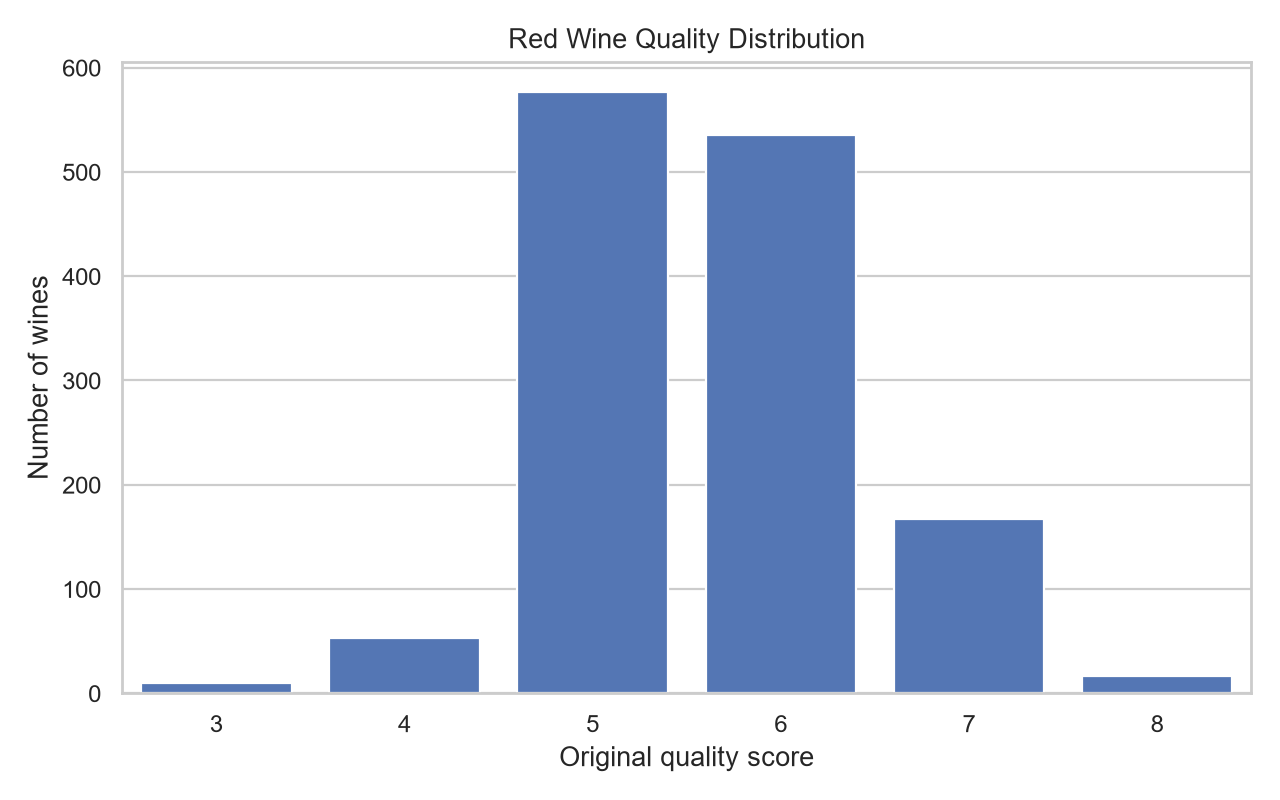

correlation_heatmap.png


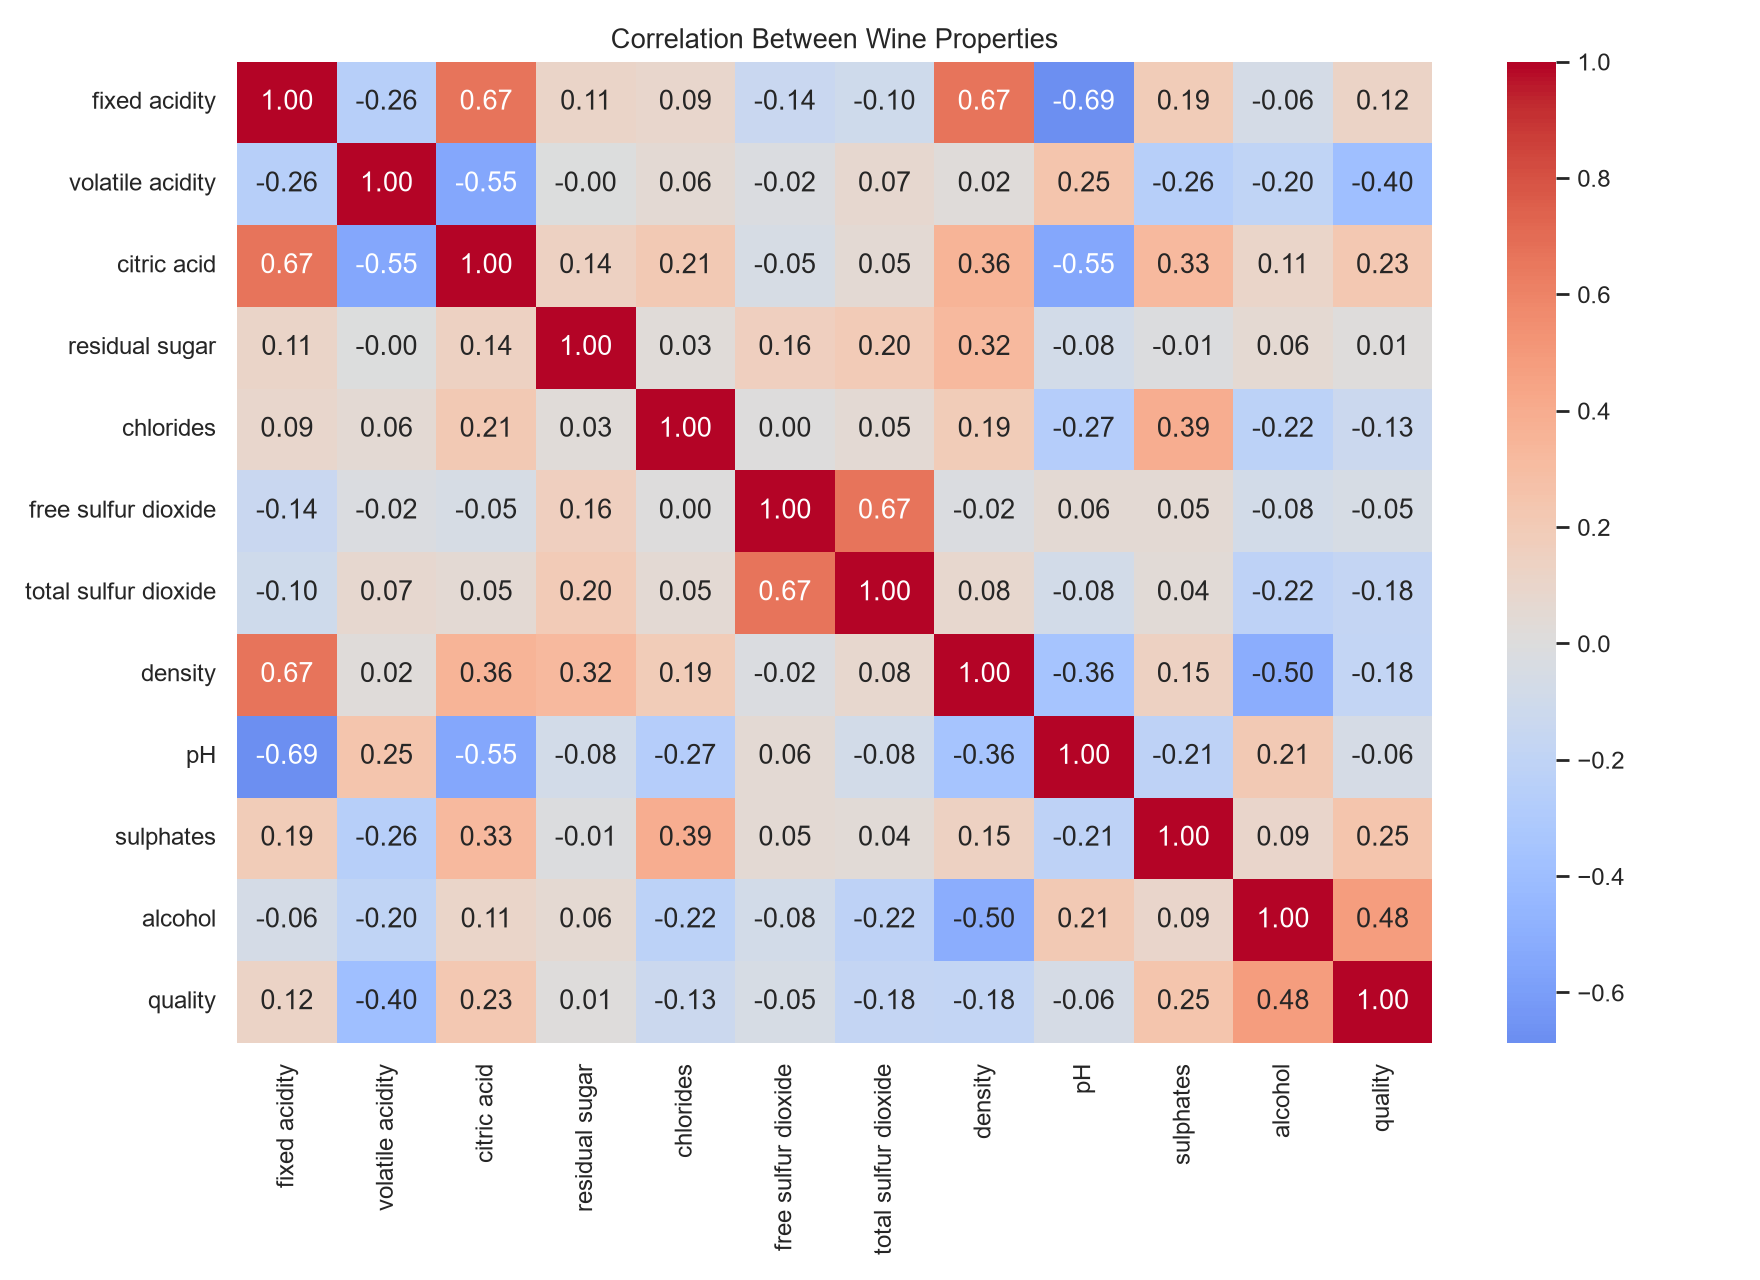

alcohol_vs_quality.png


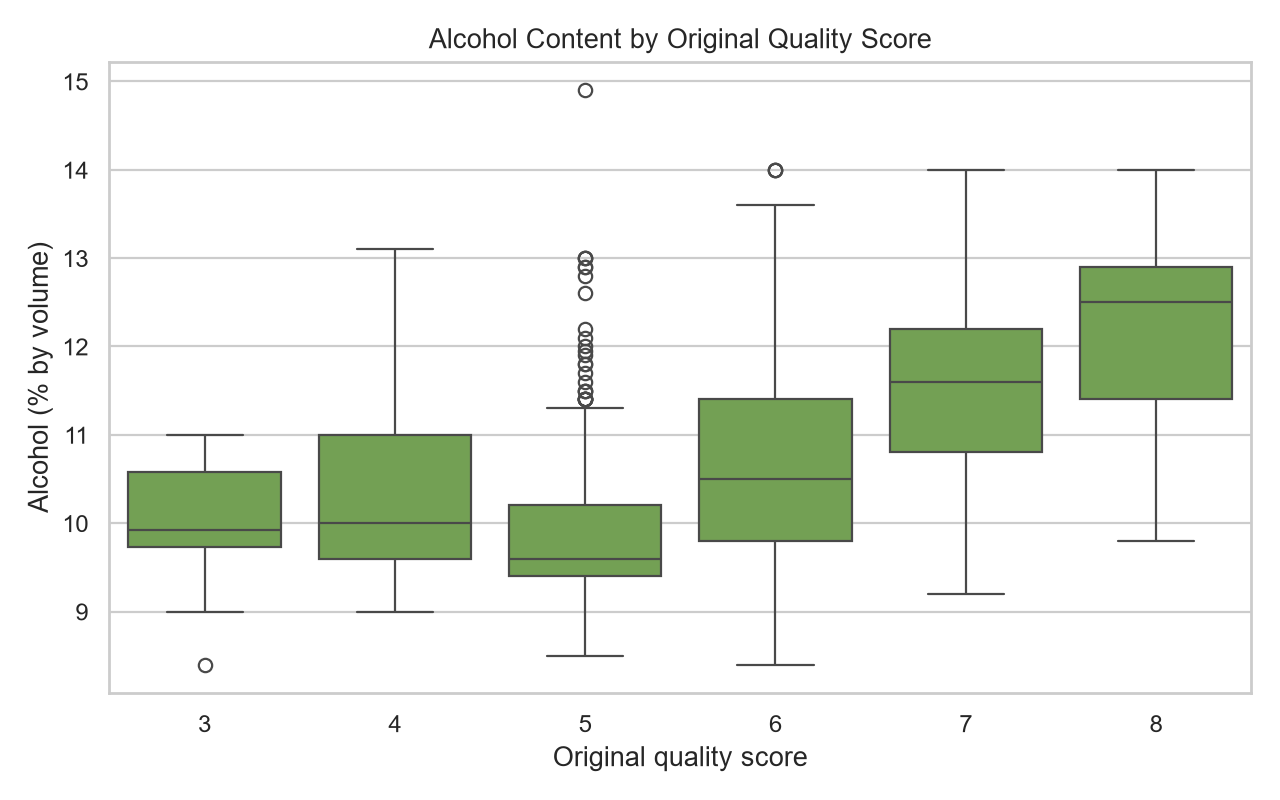

acidity_analysis.png


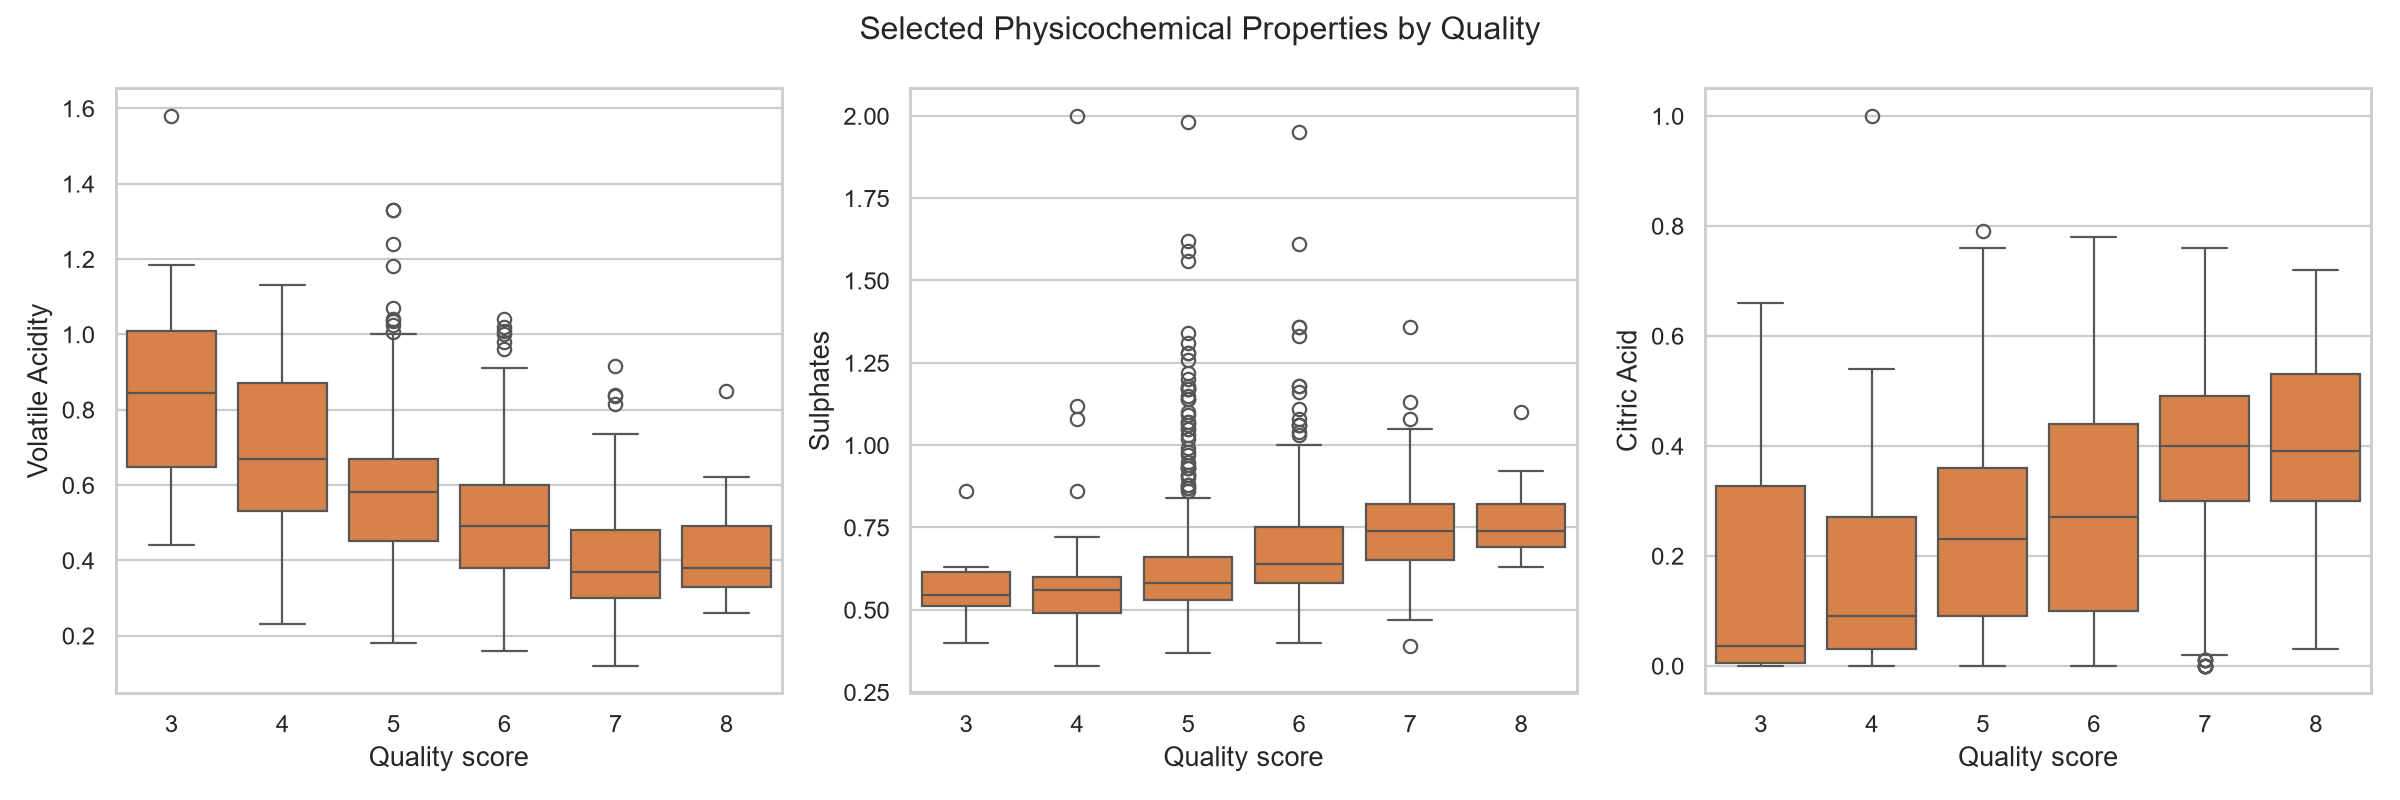

Features most correlated with the original quality score:


,correlation
alcohol,0.480343
volatile acidity,-0.395214
sulphates,0.248835
citric acid,0.228057
density,-0.184252


In [4]:
print("Mean, median, standard deviation, minimum, and maximum:")
display(data.drop(columns="quality_label").agg(["mean", "median", "std", "min", "max"]).T)
create_eda_charts(data, VISUALIZATIONS_PATH)
for filename in ["quality_distribution.png", "correlation_heatmap.png", "alcohol_vs_quality.png", "acidity_analysis.png"]:
    print(filename)
    display(Image(filename=str(VISUALIZATIONS_PATH / filename)))
quality_correlations = data.drop(columns="quality_label").corr()["quality"].drop("quality").sort_values(key=abs, ascending=False)
print("Features most correlated with the original quality score:")
display(quality_correlations.head(5).to_frame("correlation"))

### EDA observations
The distribution chart shows how frequently each original score occurs; the score categories are unevenly represented. The correlation heatmap highlights linear relationships, while the feature charts compare measured distributions across quality scores. Inspect the displayed counts and correlation table above before drawing conclusions; correlation alone does not establish cause.

## Feature engineering and data preprocessing
The original score is grouped into a three-class classification target. Feature columns exclude both the original score and the derived label. One stratified 80:20 split with random state 42 is reused for every model. Scaling is fitted inside the SVC and SGD pipelines, preventing test data from influencing it.

In [5]:
print("Grouped target distribution:")
display(data["quality_label"].value_counts().rename_axis("quality_label").to_frame("count"))
X_train, X_test, y_train, y_test = split_features_target(data, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train class proportions:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("proportion"))

Grouped target distribution:


,count
quality_label,
Low Quality,640
Medium Quality,535
High Quality,184


Train shape: (1087, 11) Test shape: (272, 11)
Train class proportions:


,proportion
quality_label,
High Quality,0.135235
Low Quality,0.471021
Medium Quality,0.393744


## Train three models
The same split is used for Random Forest, an RBF-kernel SVC, and an SGD Classifier with modified Huber loss. Class weighting is used to account for uneven class frequencies.

In [6]:
models = train_models(X_train, y_train, MODELS_PATH, random_state=42)
print("Trained and saved:", list(models))
print("Model files:", sorted(path.name for path in MODELS_PATH.glob("*.joblib")))

Trained and saved: ['Random Forest', 'SVC', 'SGD']
Model files: ['random_forest_model.joblib', 'sgd_model.joblib', 'svm_model.joblib']


## Model evaluation and comparison
Accuracy is the share of all correct predictions. Precision measures how often predictions of a class are correct; recall measures how many examples of a class are found; F1 balances precision and recall. Macro averages calculate each class equally.

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Random Forest,0.610294,0.602661,0.597970,0.599864
1,SVC,0.591912,0.564855,0.609818,0.580364
2,SGD,0.463235,0.451923,0.498707,0.442841


Classification reports saved to reports/classification_reports.txt


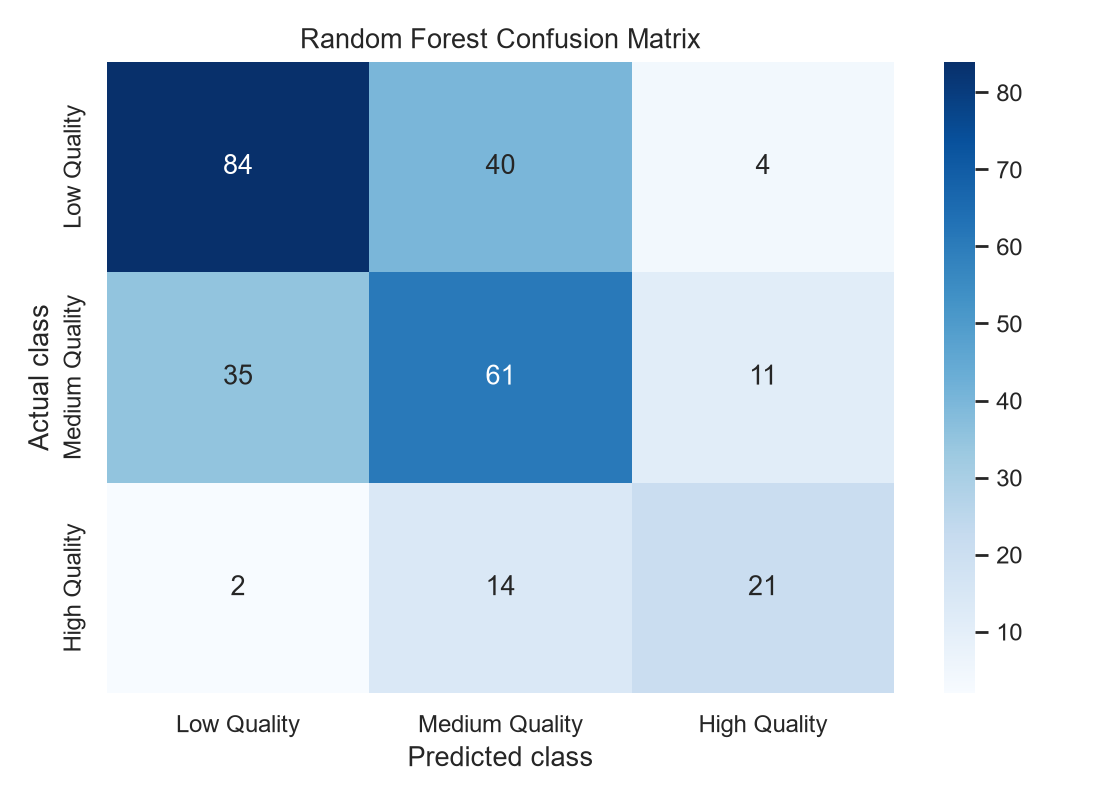

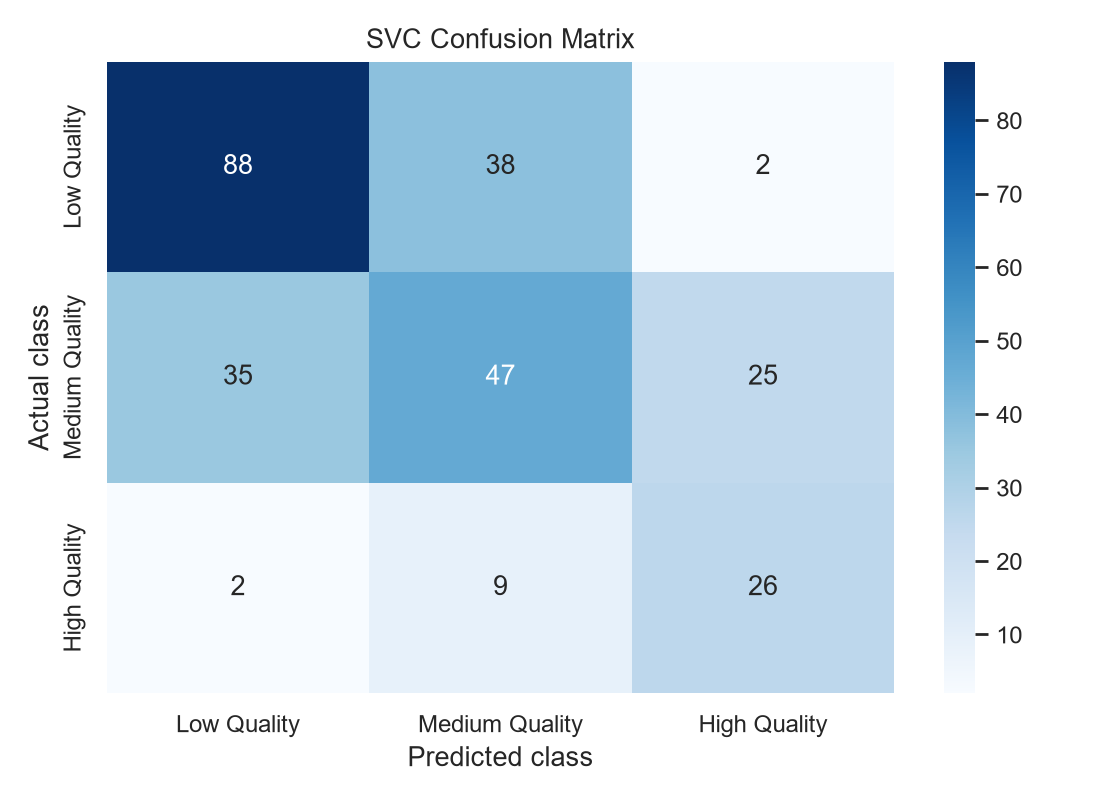

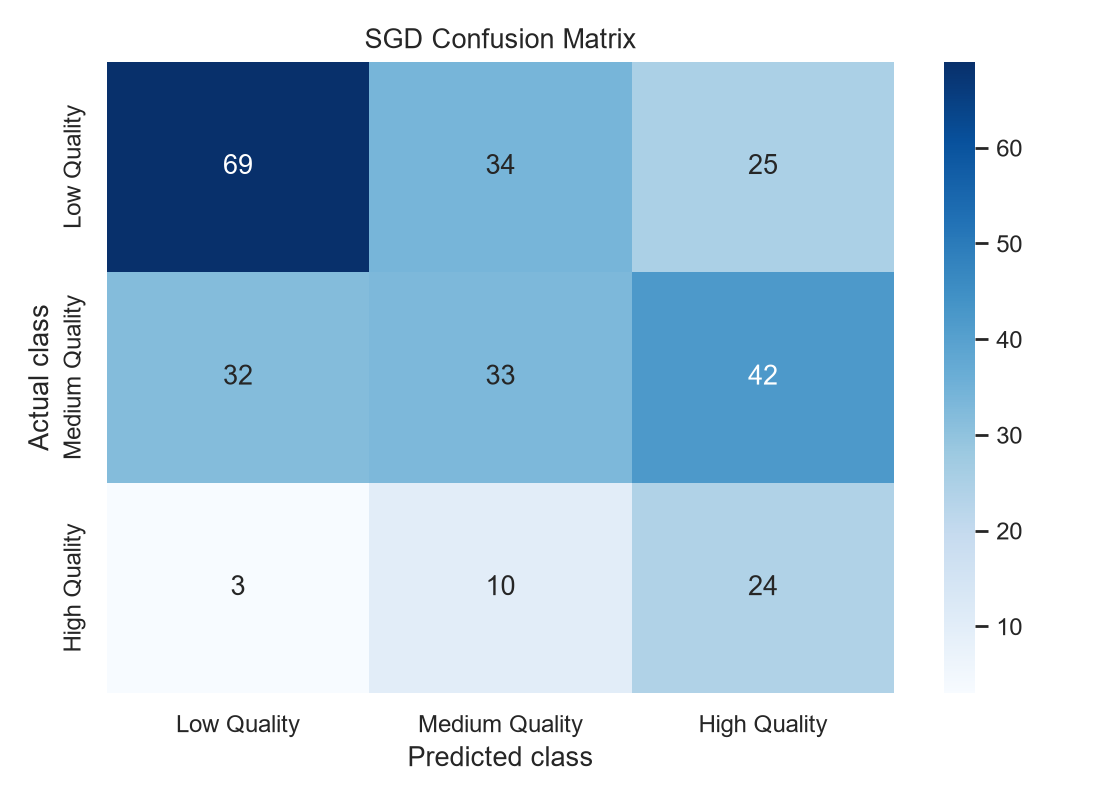

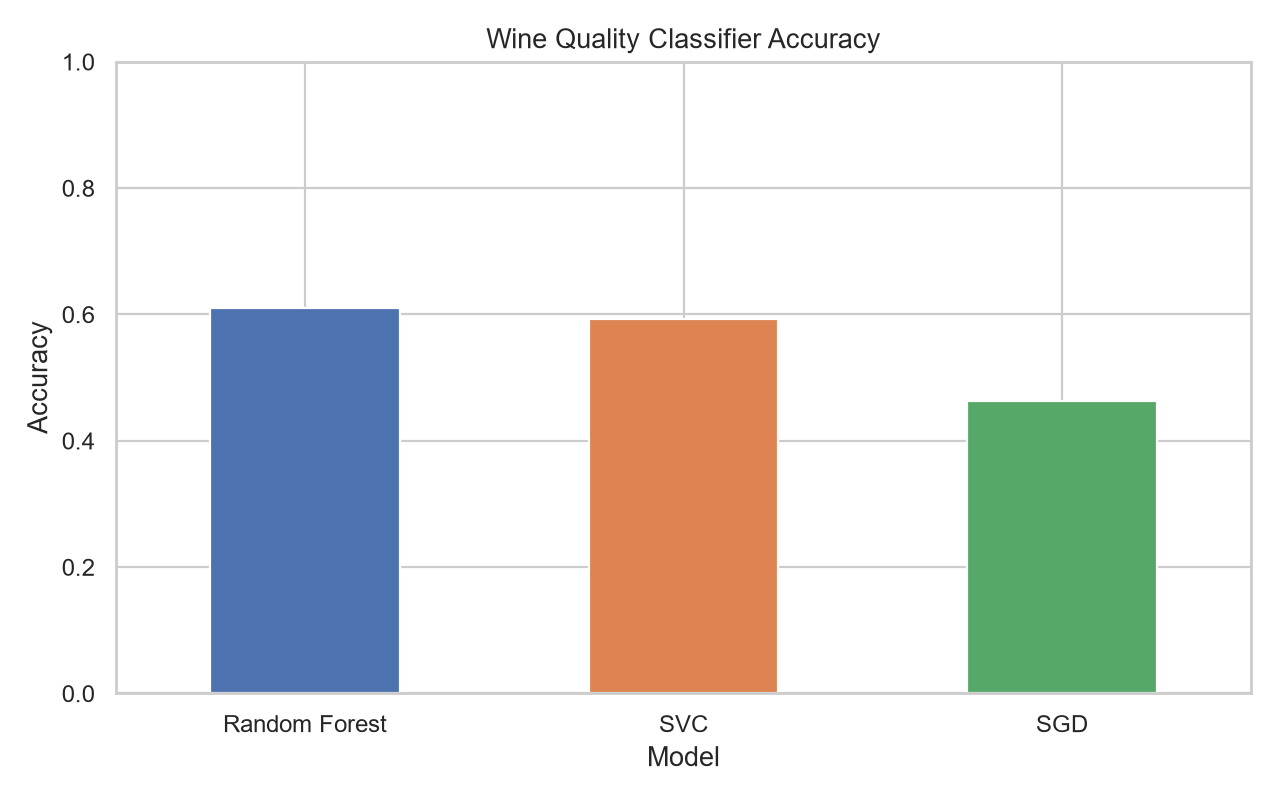

Best by macro F1: Random Forest (macro F1=0.600)


In [7]:
comparison, predictions = evaluate_models(models, X_test, y_test, REPORTS_PATH, VISUALIZATIONS_PATH)
display(comparison)
print("Classification reports saved to reports/classification_reports.txt")
for filename in ["random_forest_confusion_matrix.png", "svm_confusion_matrix.png", "sgd_confusion_matrix.png", "model_accuracy_comparison.png"]:
    display(Image(filename=str(VISUALIZATIONS_PATH / filename)))
best_model = comparison.iloc[0]
print(f"Best by macro F1: {best_model['Model']} (macro F1={best_model['F1-score (Macro)']:.3f})")

## Random Forest feature importance
The chart below ranks the Random Forest's internal feature importances. These indicate how the fitted forest used features when making splits; they do not prove that a feature causes wine quality.

,importance
alcohol,0.176510
sulphates,0.125540
volatile acidity,0.105414
density,0.087607
total sulfur dioxide,0.085522
citric acid,0.079776
chlorides,0.075861
fixed acidity,0.069900
pH,0.068956
free sulfur dioxide,0.062981


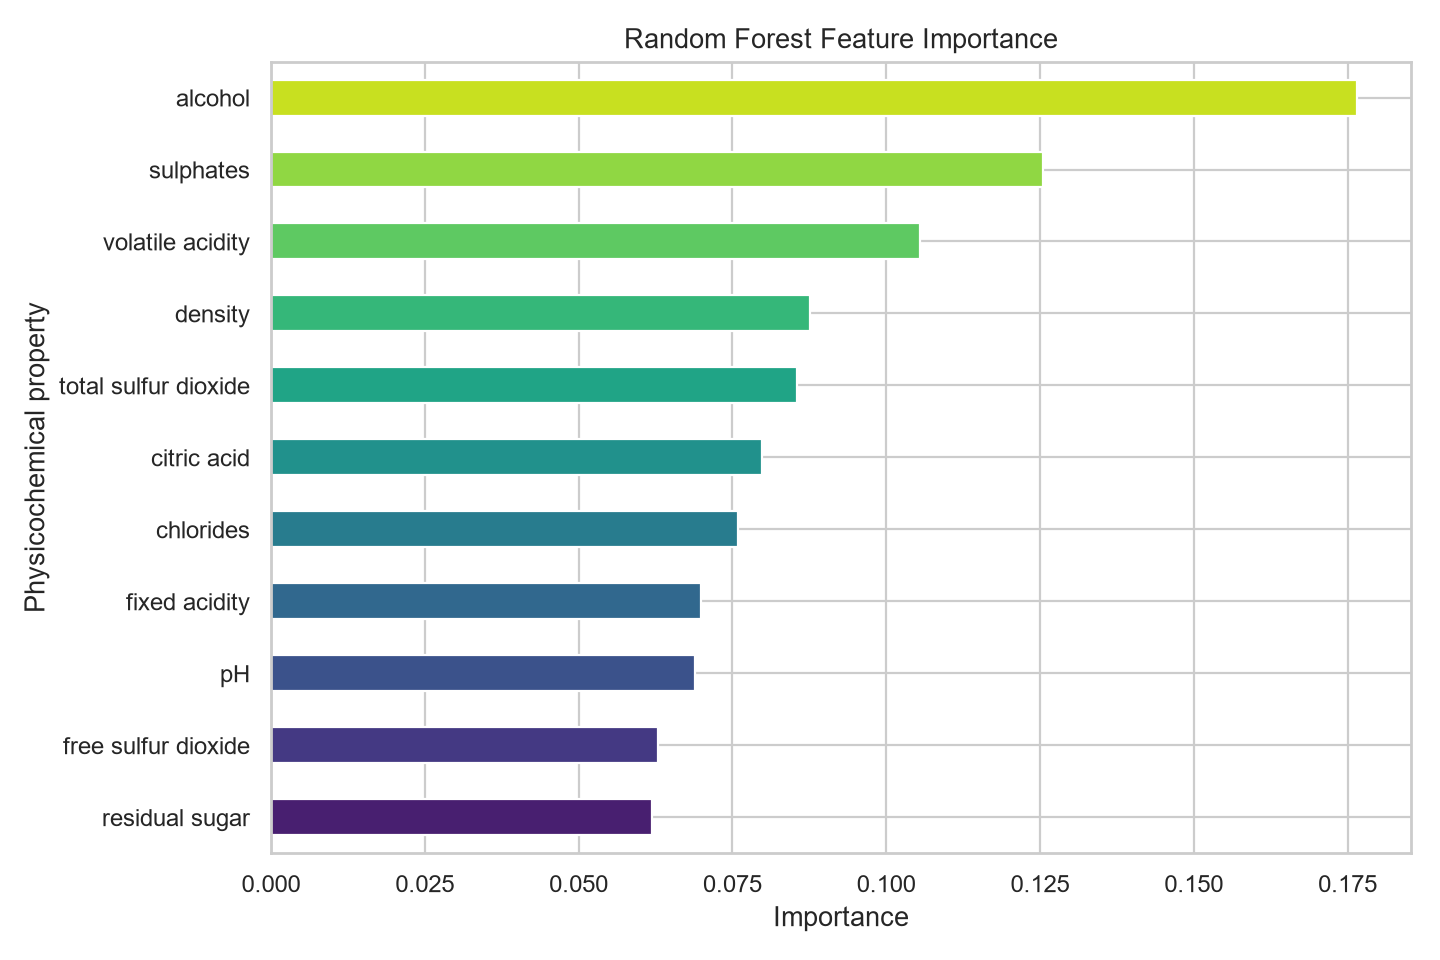

In [8]:
feature_importance = save_feature_importance(models["Random Forest"], X_train.columns, VISUALIZATIONS_PATH)
display(feature_importance.head(10).to_frame("importance"))
display(Image(filename=str(VISUALIZATIONS_PATH / "feature_importance.png")))

## Prediction demonstration and findings
Use the first actual held-out test row to demonstrate a prediction. The generated findings file records class distribution, correlations, model metrics, feature importances, and limitations from this run.

In [9]:
sample = X_test.iloc[[0]]
actual_class = y_test.iloc[0]
predicted_class = models[best_model["Model"]].predict(sample)[0]
print("Actual quality class:", actual_class)
print("Predicted quality class:", predicted_class)
print("Correct prediction:", actual_class == predicted_class)

write_findings(data, audit, comparison, feature_importance, REPORTS_PATH)
print(f"Findings saved to {REPORTS_PATH / 'key_findings.md'}")
print((REPORTS_PATH / "key_findings.md").read_text(encoding="utf-8"))

Actual quality class: Medium Quality
Predicted quality class: Medium Quality
Correct prediction: True
Findings saved to C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L2-WineQualityPrediction\reports\key_findings.md
# Wine Quality Prediction: Key Findings

These findings are generated from the downloaded UCI red wine dataset and the held-out test results.

- **Data cleaning:** 1,599 rows loaded; 240 duplicate rows removed; 1,359 rows retained.
- **Most common class:** Low Quality (640 wines; 47.1% of cleaned records).
- **Class distribution:** Low Quality: 640, Medium Quality: 535, High Quality: 184.
- **Feature correlations with original quality:** strongest by absolute linear correlation are alcohol (0.480) and volatile acidity (-0.395). Correlation is descriptive and does not imply causation.
- **Best model by macro F1-score:** Random Forest (accuracy 0.610; macro precision 0.603; macro recall 0.598; macro F1 0.600).
- **Class imbalance:** the three grouped classes are not equall

## Conclusion
The notebook explored and cleaned the UCI red wine data, derived the requested three-class target, and compared three classifiers using a shared stratified test split. Consult the computed comparison table and reports for this run's measured performance. The dataset is limited to Portuguese red wines and the grouped target simplifies an ordinal score; these models should not be treated as validated wine-quality assessments outside this dataset.